In [1]:
import requests
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

 
URL = "https://github.com/bigdatawirtz/datasets/raw/refs/heads/main/datasets/meteo_alvedro_2021_2025.csv"
resposta = requests.get(URL, timeout=30)
resposta.raise_for_status()
RUTA = Path("../datos/raw/meteo_alvedro_2021_2025.csv")
RUTA.write_bytes(resposta.content)   # bytes: tal como chega


81825

In [2]:
print(RUTA.read_bytes()[:120])


b'Servizo de exportaci\xf3n de datos meteorol\xf3xicos\nEstaci\xf3n: A Coru\xf1a / Alvedro (aeroporto) \xb7 Indicativo: 08002\nLatitude: 43'


In [3]:

with open(RUTA, encoding="latin-1") as f:
    for _ in range(8):
        print(f.readline().rstrip())

Servizo de exportación de datos meteorolóxicos
Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002
Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m
Período: 01/01/2021 - 31/12/2025
Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins didácticos.

Data;Temp. media (ºC);Temp. mínima (ºC);Temp. máxima (ºC);Humidade relativa (%);Precipitación (mm);Vento medio (km/h);Presión (hPa)
2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7


In [4]:
meteo = pd.read_csv(
    RUTA,
    encoding="latin-1",
    skiprows=6,
    sep=";",
    decimal=",",
    na_values=["-", "", "NA", "Ip"],
    thousands="."
)
meteo.head()

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,12.2,11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,9.8,6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,12.4,8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,4.7,7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,1.2,6.2,1014.6


In [5]:
meteo.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Data                   1812 non-null   str    
 1   Temp. media (ºC)       1803 non-null   float64
 2   Temp. mínima (ºC)      1806 non-null   float64
 3   Temp. máxima (ºC)      1803 non-null   float64
 4   Humidade relativa (%)  1812 non-null   int64  
 5   Precipitación (mm)     1683 non-null   float64
 6   Vento medio (km/h)     1812 non-null   float64
 7   Presión (hPa)          1811 non-null   float64
dtypes: float64(6), int64(1), str(1)
memory usage: 113.4 KB


In [6]:
meteo = meteo.rename(columns={
    "Data": "data",
    "Temp. media (ºC)": "tmed",
    "Temp. mínima (ºC)": "tmin",
    "Temp. máxima (ºC)": "tmax",
    "Humidade relativa (%)": "hum",
    "Precipitación (mm)": "prec",
    "Vento medio (km/h)": "vento",
    "Presión (hPa)": "presion",
})
meteo.columns.tolist()

['data', 'tmed', 'tmin', 'tmax', 'hum', 'prec', 'vento', 'presion']

In [7]:
meteo["data"] = pd.to_datetime(meteo["data"], format="mixed")
meteo.dtypes



data       datetime64[us]
tmed              float64
tmin              float64
tmax              float64
hum                 int64
prec              float64
vento             float64
presion           float64
dtype: object

In [8]:
print("Filas duplicadas:", meteo.duplicated().sum())
print("Datas repetidas:", meteo["data"].duplicated().sum())
meteo = meteo.drop_duplicates()

Filas duplicadas: 8
Datas repetidas: 45


In [9]:
meteo.describe().round(1)

,data,tmed,tmin,tmax,hum,prec,vento,presion
count,1804,1795.0,1798.0,1795.0,1804.0,1676.0,1804.0,1803.0
mean,2023-06-29 14:51:37.117516,-2.2,-23.1,2.5,80.2,-8.8,11.9,1018.2
min,2021-01-01 00:00:00,-9999.0,-9999.0,-9999.0,36.0,-9999.0,3.2,987.9
25%,2022-03-28 18:00:00,11.3,7.1,15.4,76.0,0.0,8.1,1014.4
50%,2023-05-27 12:00:00,14.7,10.9,18.9,81.0,0.2,10.4,1018.5
75%,2024-10-07 06:00:00,18.0,14.0,22.8,86.0,3.2,14.9,1022.5
max,2025-12-31 00:00:00,31.3,21.1,39.2,100.0,58.7,38.5,1037.9
std,NaN,409.2,577.4,409.4,8.1,345.5,5.2,7.4


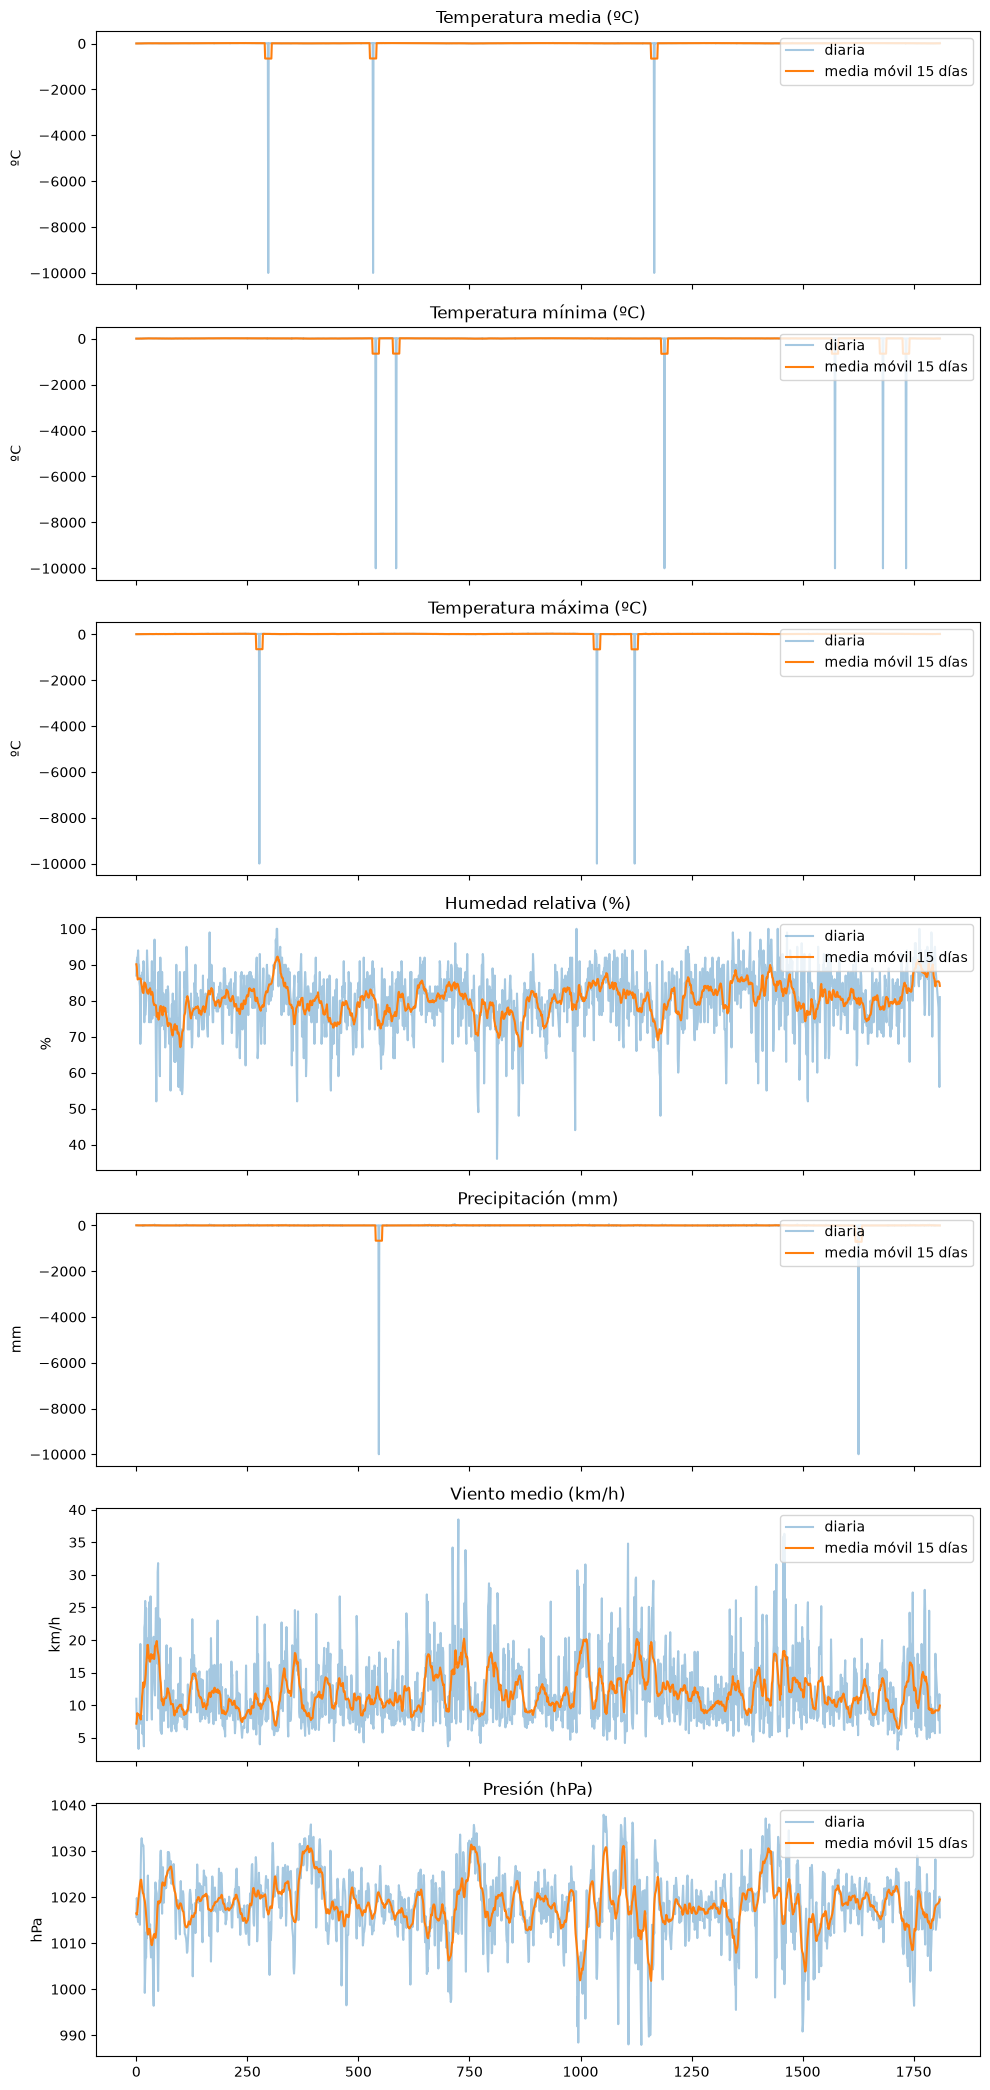

In [10]:
variables = {
    "tmed": "Temperatura media (ºC)",
    "tmin": "Temperatura mínima (ºC)",
    "tmax": "Temperatura máxima (ºC)",
    "hum": "Humedad relativa (%)",
    "prec": "Precipitación (mm)",
    "vento": "Viento medio (km/h)",
    "presion": "Presión (hPa)",
}

fig, axes = plt.subplots(len(variables), 1, figsize=(10, 3 * len(variables)), sharex=True)

for ax, (col, titulo) in zip(axes, variables.items()):
    meteo[col].plot(ax=ax, alpha=0.4, label="diaria")
    meteo[col].rolling(15, center=True, min_periods=7).mean().plot(ax=ax, label="media móvil 15 días")
    ax.set_title(titulo)
    ax.set_ylabel(titulo.split("(")[1].rstrip(")")) 
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [11]:
imposibles = (meteo["prec"] < 0) | (meteo["tmin"] < -273) | (meteo["tmed"] < 0) | (meteo["tmax"] < 0) \
           | (meteo["tmed"] > meteo["tmax"]) | (meteo["tmed"] < meteo["tmin"])
print("Valores imposibles:", imposibles.sum())
meteo.loc[meteo["prec"] < 0, "prec"] = pd.NA
meteo.loc[meteo["tmin"] < -273, "tmin"] = pd.NA
meteo.loc[meteo["tmed"] < 0, "tmed"] = pd.NA
meteo.loc[meteo["tmax"] < 0, "tmax"] = pd.NA
meteo.loc[meteo["tmed"] > meteo["tmax"], "tmed"] = pd.NA

Valores imposibles: 15


In [12]:
meteo = meteo.set_index("data").sort_index()
for col in ["tmed", "tmax", "tmin", "vento", "hum","presion"]:
    meteo[col] = meteo[col].interpolate(method="time")
meteo.isna().sum()

tmed         0
tmin         0
tmax         0
hum          0
prec       130
vento        0
presion      0
dtype: int64

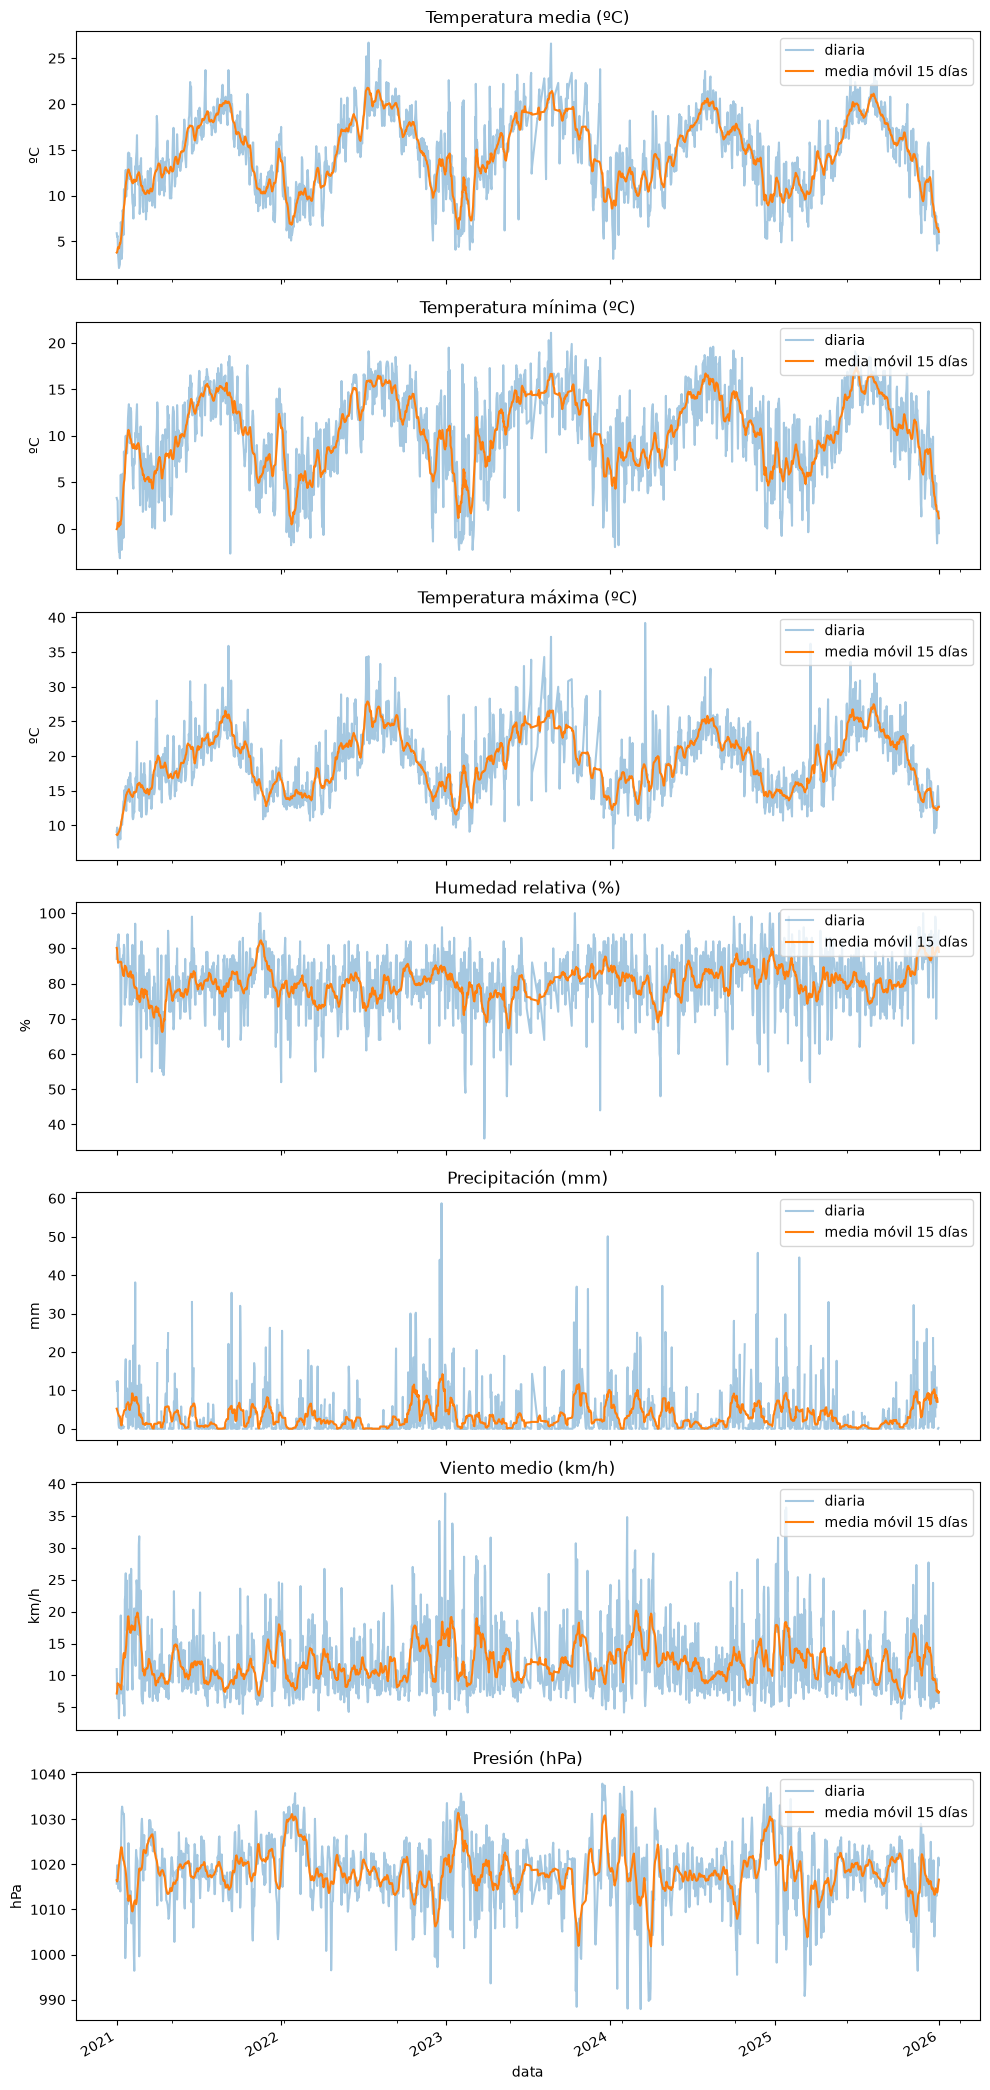

In [13]:
variables = {
    "tmed": "Temperatura media (ºC)",
    "tmin": "Temperatura mínima (ºC)",
    "tmax": "Temperatura máxima (ºC)",
    "hum": "Humedad relativa (%)",
    "prec": "Precipitación (mm)",
    "vento": "Viento medio (km/h)",
    "presion": "Presión (hPa)",
}

fig, axes = plt.subplots(len(variables), 1, figsize=(10, 3 * len(variables)), sharex=True)

for ax, (col, titulo) in zip(axes, variables.items()):
    meteo[col].plot(ax=ax, alpha=0.4, label="diaria")
    meteo[col].rolling(15, center=True, min_periods=7).mean().plot(ax=ax, label="media móvil 15 días")
    ax.set_title(titulo)
    ax.set_ylabel(titulo.split("(")[1].rstrip(")")) 
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [14]:
limpo = Path("../datos/clean")
limpo.mkdir(exist_ok=True)
meteo.to_csv(limpo / "meteo_alvedro_2021_2025")  
print("Gardado:", limpo / "meteo_alvedro_2021_2025")

Gardado: ../datos/clean/meteo_alvedro_2021_2025


In [15]:
anual = meteo.resample("YS").agg({
    "tmed": "mean"
})

anual.index = anual.index.year

anual.round(1)


,tmed
data,
2021,14.1
2022,15.0
2023,14.9
2024,14.5
2025,14.4


In [16]:
mensual = meteo.groupby(meteo.index.month).agg({
    "prec": "mean"
})

MESES = [
    "ene", "feb", "mar", "abr", "may", "jun",
    "jul", "ago", "sep", "oct", "nov", "dic"
]

mensual.index = [MESES[m - 1] for m in mensual.index]

display(mensual.round(1))

print("Mes más lluvioso:", mensual["prec"].idxmax())
print("Mes más seco:", mensual["prec"].idxmin())


,prec
ene,4.4
feb,3.6
mar,3.1
abr,3.0
may,2.2
jun,1.8
jul,0.7
ago,0.6
sep,2.6
oct,5.5


Mes más lluvioso: oct
Mes más seco: ago


In [17]:

dias_lluvia = (
    meteo.assign(
        dia_lluvia=meteo["prec"] >= 1
    )
    .groupby(meteo.index.month)["dia_lluvia"]
    .sum()
)

dias_lluvia.index = [MESES[m - 1] for m in dias_lluvia.index]

dias_lluvia


ene    74
feb    55
mar    60
abr    52
may    53
jun    43
jul    25
ago    24
sep    56
oct    72
nov    72
dic    65
Name: dia_lluvia, dtype: int64

In [18]:
idx_calor = meteo.groupby(
    meteo.index.year
)["tmax"].idxmax()

dias_calientes = meteo.loc[
    idx_calor, ["tmax"]
].sort_index()

print("Día más caliente de cada año:")
display(dias_calientes)

idx_frio = meteo.groupby(
    meteo.index.year
)["tmin"].idxmin()

dias_frios = meteo.loc[
    idx_frio, ["tmin"]
].sort_index()

print("Día más frío de cada año:")
display(dias_frios)

Día más caliente de cada año:


,tmax
data,
2021-09-06,35.9
2022-07-14,34.4
2023-08-23,37.2
2024-03-19,39.2
2025-03-21,36.2


Día más frío de cada año:


,tmin
data,
2021-01-08,-3.2
2022-01-23,-1.8
2023-01-31,-2.3
2024-01-12,-2.0
2025-12-27,-1.6


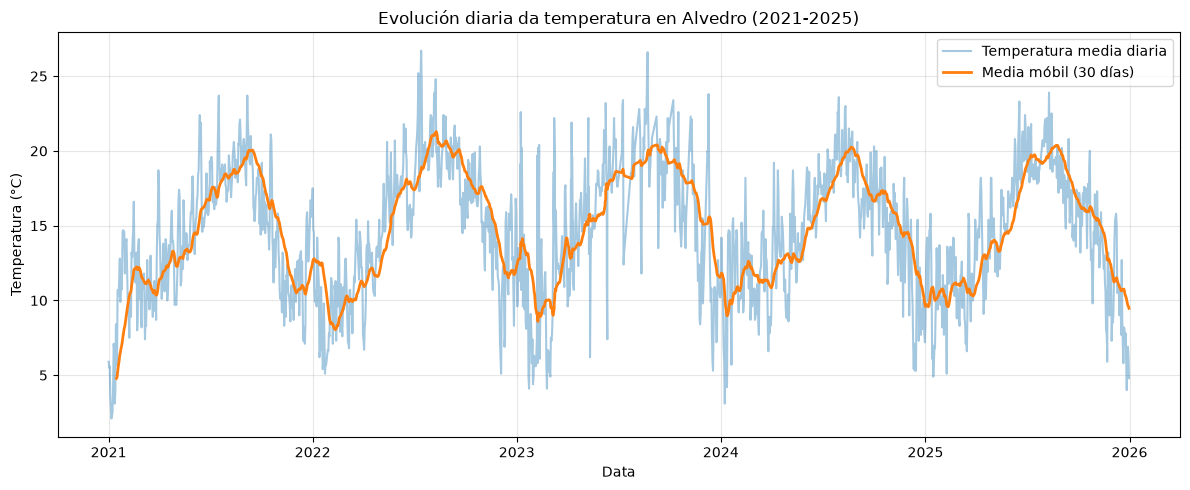

In [19]:
import matplotlib.pyplot as plt

media_movil = meteo["tmed"].rolling(window=30, min_periods=15).mean()

plt.figure(figsize=(12, 5))
plt.plot(meteo.index, meteo["tmed"], label="Temperatura media diaria", alpha=0.4)
plt.plot(meteo.index, media_movil, label="Media móbil (30 días)", linewidth=2)

plt.title("Evolución diaria da temperatura en Alvedro (2021-2025)")
plt.xlabel("Data")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

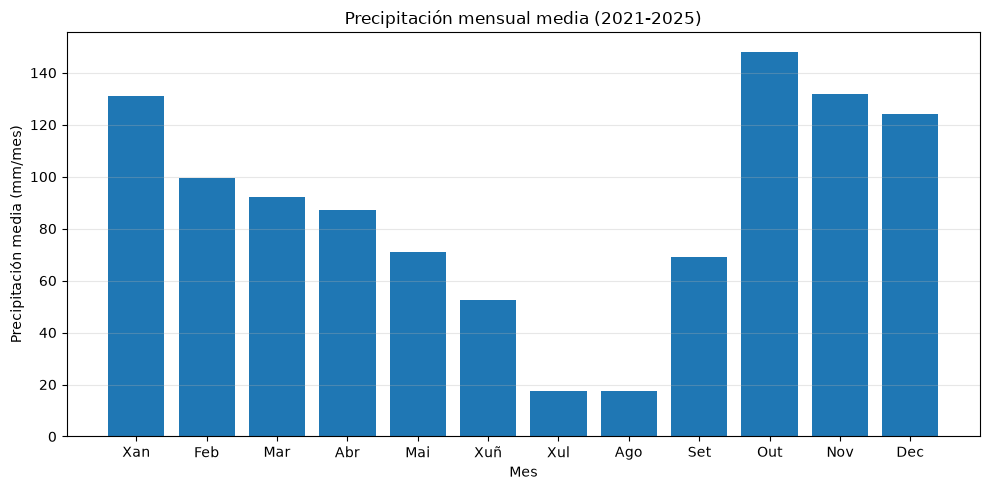

In [20]:
prec_mensual = meteo["prec"].groupby(
    [meteo.index.year, meteo.index.month]
).sum(min_count=1)

prec_media = prec_mensual.groupby(level=1).mean()

MESES = [
    "Xan", "Feb", "Mar", "Abr", "Mai", "Xuñ",
    "Xul", "Ago", "Set", "Out", "Nov", "Dec"
]

prec_media.index = [MESES[m - 1] for m in prec_media.index]

plt.figure(figsize=(10, 5))
plt.bar(prec_media.index, prec_media.values)

plt.title("Precipitación mensual media (2021-2025)")
plt.xlabel("Mes")
plt.ylabel("Precipitación media (mm/mes)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

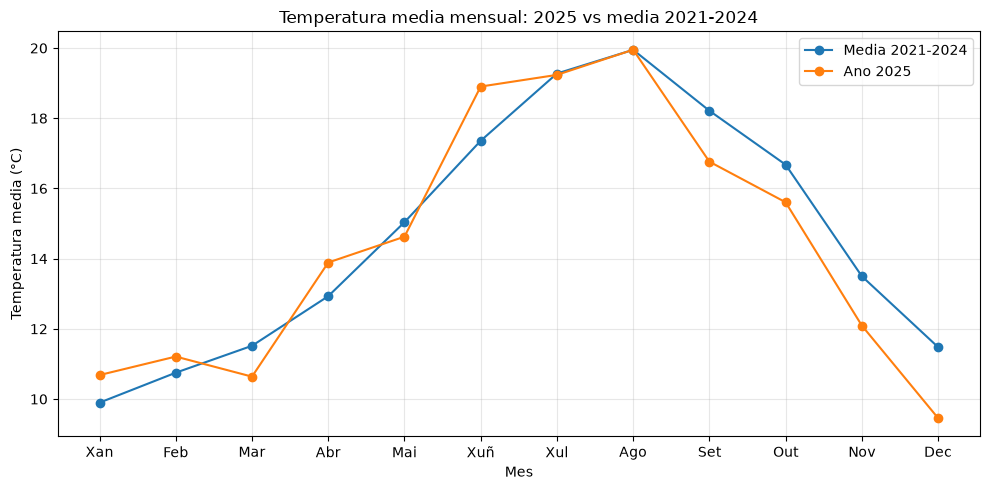

In [21]:
temp_mensual = meteo["tmed"].groupby(
    [meteo.index.year, meteo.index.month]
).mean()

media_anterior = temp_mensual[
    temp_mensual.index.get_level_values(0) < 2025
].groupby(level=1).mean()

temp_2025 = temp_mensual[
    temp_mensual.index.get_level_values(0) == 2025
]
temp_2025.index = temp_2025.index.get_level_values(1)

meses = sorted(set(media_anterior.index) & set(temp_2025.index))
n_meses = [MESES[m - 1] for m in meses]

plt.figure(figsize=(10, 5))
plt.plot(
    n_meses,
    [media_anterior.loc[m] for m in meses],
    marker="o",
    label="Media 2021-2024"
)
plt.plot(
    n_meses,
    [temp_2025.loc[m] for m in meses],
    marker="o",
    label="Ano 2025"
)

plt.title("Temperatura media mensual: 2025 vs media 2021-2024")
plt.xlabel("Mes")
plt.ylabel("Temperatura media (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
def amplitud_bucle(dataFrame):
    amplitudes = []

    for i in range(len(dataFrame)):
        amplitud = dataFrame["tmax"].iloc[i] - dataFrame["tmin"].iloc[i]
        amplitudes.append(amplitud)

    return amplitudes

%timeit amplitud_bucle(meteo)

49 ms ± 2.22 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [23]:
def amplitud_vectorizada(dataFrame):
    return dataFrame["tmax"] - dataFrame["tmin"]

%timeit amplitud_vectorizada(meteo)

110 μs ± 14.8 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [24]:
meteo_grande = pd.concat([meteo] * 5, ignore_index=True)

In [25]:
%timeit amplitud_bucle(meteo_grande)
%timeit amplitud_vectorizada(meteo_grande)

267 ms ± 26.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
101 μs ± 12.6 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [37]:
from sqlalchemy import create_engine, text

user = "user"
password = "changeme"
host = "localhost"
port = "5432"
bd = "bd"

connection = create_engine(
    f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{bd}"
)

In [38]:
with connection.connect() as conexion:
    resultado = conexion.execute(text("SELECT version();"))
    print(resultado.scalar())

PostgreSQL 17.11 (Debian 17.11-1.pgdg13+2) on x86_64-pc-linux-gnu, compiled by gcc (Debian 14.2.0-19) 14.2.0, 64-bit


In [39]:
meteo.to_sql(
    name="meteo",
    con=connection,
    if_exists="replace",
    index=True,
    index_label="data"
)

804

In [40]:
with connection.connect() as conexion:
    resultado = conexion.execute(
        text("SELECT COUNT(*) FROM meteo;")
    )
    print("Filas cargadas:", resultado.scalar())

Filas cargadas: 1804


In [ ]:
with connection.connect() as conexion:
    muestra = pd.read_sql(
        text("SELECT * FROM meteo LIMIT 5;"),
        conexion
    )

display(muestra)

,data,tmed,tmin,tmax,hum,prec,vento,presion
0,2021-01-01,5.9,3.3,9.1,87,12.2,11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,9.8,6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,12.4,8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,4.7,7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,1.2,6.2,1014.6


In [49]:
consulta1 = """
SELECT
    EXTRACT(YEAR FROM data) AS ano,
    ROUND(AVG(tmed)::numeric, 2) AS temperatura_media
FROM meteo
GROUP BY EXTRACT(YEAR FROM data)
ORDER BY ano;
"""

with connection.connect() as conexion:
    resultado_sql1 = pd.read_sql(text(consulta1), conexion)

display(resultado_sql1)

resultado_pandas1 = (
    meteo.groupby(meteo.index.year)["tmed"]
    .mean()
    .round(2)
)

display(resultado_pandas1)

,ano,temperatura_media
0,2021.0,14.13
1,2022.0,14.99
2,2023.0,14.91
3,2024.0,14.46
4,2025.0,14.43


data
2021    14.13
2022    14.99
2023    14.91
2024    14.46
2025    14.43
Name: tmed, dtype: float64

In [ ]:
consulta2 = """
WITH precipitacion_mensual AS (
    SELECT
        EXTRACT(YEAR FROM data) AS ano,
        EXTRACT(MONTH FROM data) AS mes,
        SUM(prec) AS total_mm
    FROM meteo
    GROUP BY
        EXTRACT(YEAR FROM data),
        EXTRACT(MONTH FROM data)
)
SELECT
    mes,
    ROUND(AVG(total_mm)::numeric, 2) AS precipitacion_media_mm
FROM precipitacion_mensual
GROUP BY mes
ORDER BY mes;
"""

with connection.connect() as conexion:
    resultado_sql2 = pd.read_sql(text(consulta2), conexion)

display(resultado_sql2)
prec_mensual = meteo["prec"].groupby(
    [meteo.index.year, meteo.index.month]
).sum(min_count=1)

prec_media_pandas = (
    prec_mensual.groupby(level=1)
    .mean()
    .round(2)
)

display(prec_media_pandas)

,mes,precipitacion_media_mm
0,1.0,131.06
1,2.0,99.56
2,3.0,92.04
3,4.0,87.28
4,5.0,70.98
5,6.0,52.72
6,7.0,17.34
7,8.0,17.62
8,9.0,68.90
9,10.0,148.16


data
1     131.06
2      99.56
3      92.04
4      87.28
5      70.98
6      52.72
7      17.34
8      17.62
9      68.90
10    148.16
11    131.84
12    124.16
Name: prec, dtype: float64

In [46]:
MESES = [
    "Xaneiro", "Febreiro", "Marzo", "Abril",
    "Maio", "Xuño", "Xullo", "Agosto",
    "Setembro", "Outubro", "Novembro", "Decembro"
]

fila_max = resultado_sql2.loc[
    resultado_sql2["precipitacion_media_mm"].idxmax()
]
fila_min = resultado_sql2.loc[
    resultado_sql2["precipitacion_media_mm"].idxmin()
]

print("Mes máis chuvioso:", MESES[int(fila_max["mes"]) - 1])
print("Mes máis seco:", MESES[int(fila_min["mes"]) - 1])

Mes máis chuvioso: Outubro
Mes máis seco: Xullo


In [51]:
consulta3 = """
SELECT
    EXTRACT(YEAR FROM data) AS ano,
    MAX(tmax) AS temperatura_maxima
FROM meteo
GROUP BY EXTRACT(YEAR FROM data)
ORDER BY ano;
"""

with connection.connect() as conexion:
    resultado_sql3 = pd.read_sql(text(consulta3), conexion)

display(resultado_sql3)
resultado_pandas3 = (
    meteo.groupby(meteo.index.year)["tmax"]
    .max()
)

display(resultado_pandas3)

,ano,temperatura_maxima
0,2021.0,35.9
1,2022.0,34.4
2,2023.0,37.2
3,2024.0,39.2
4,2025.0,36.2


data
2021    35.9
2022    34.4
2023    37.2
2024    39.2
2025    36.2
Name: tmax, dtype: float64